In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('../data/credit_cleaned.csv')
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
# Check skewness of all numerical columns
print(df.select_dtypes(include=['int64', 'float64']).skew())

SeriousDlqin2yrs                          3.462561
RevolvingUtilizationOfUnsecuredLines     97.381355
age                                       0.192669
NumberOfTime30-59DaysPastDueNotWorse      4.239362
DebtRatio                                94.933163
MonthlyIncome                           126.823945
NumberOfOpenCreditLinesAndLoans           1.223351
NumberOfTimes90DaysLate                   9.324616
NumberRealEstateLoansOrLines              3.485331
NumberOfTime60-89DaysPastDueNotWorse      7.536139
NumberOfDependents                        1.618803
dtype: float64


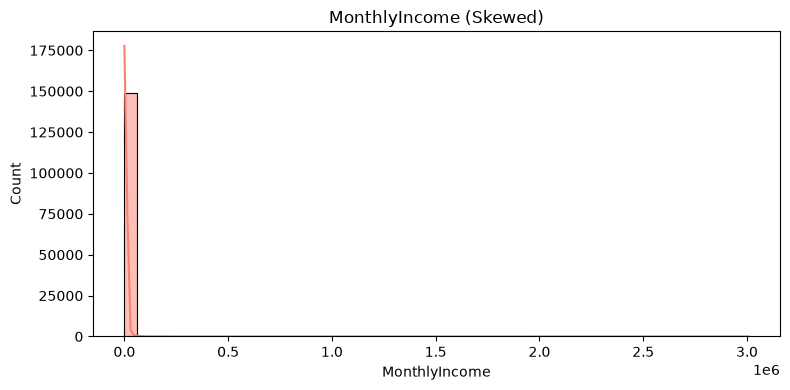

In [32]:
plt.figure(figsize=(8,4))
sns.histplot(df['MonthlyIncome'], bins=50, kde=True, color = 'salmon')
plt.title('MonthlyIncome (Skewed)')
plt.tight_layout()



In [ ]:
# Apply log transform to tame extreme skewness
df['Log_MonthlyIncome'] = np.log1p(df['MonthlyIncome'])
df['Log_Utilization'] = np.log1p(df['RevolvingUtilizationOfUnsecuredLines'])
df['Log_DebtRatio'] = np.log1p(df['DebtRatio'])

In [ ]:
# Find the 99th percentile value for DebtRatio
debt_cap_limit = df['DebtRatio'].quantile(0.99)
print(f"The 99th percentile cap limit is: {debt_cap_limit:.2f}")

The 99th percentile cap limit is: 4988.07


In [22]:
# Check counts of extreme/unreasonable values in key columns
unreasonable_checks = {
    "MonthlyIncome == 0": (df['MonthlyIncome'] == 0).sum(),
    "Utilization > 10.0 (1000%+)": (df['RevolvingUtilizationOfUnsecuredLines'] > 10.0).sum(),
    "DebtRatio > 10.0 (1000%+ Debt)": (df['DebtRatio'] > 10.0).sum(),
    "Unusually high dependents (> 10)": (df['NumberOfDependents'] > 10).sum()
}

for condition, count in unreasonable_checks.items():
    print(f"{condition}: {count} rows")

MonthlyIncome == 0: 1616 rows
Utilization > 10.0 (1000%+): 241 rows
DebtRatio > 10.0 (1000%+ Debt): 28871 rows
Unusually high dependents (> 10): 2 rows


In [24]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,Log_MonthlyIncome,Log_Utilization,Log_DebtRatio
count,149232.000000,149232.000000,149232.000000,149232.000000,149232.000000,1.492320e+05,149232.000000,149232.000000,149232.000000,149232.000000,149232.000000,149232.000000,149232.000000,149232.000000
mean,0.067037,6.077079,52.298495,0.246603,354.810628,6.426777e+03,8.488099,0.090657,1.023467,0.065033,0.741168,8.448996,0.257504,1.532747
std,0.250086,250.396892,14.713476,0.698796,2042.898332,1.292250e+04,5.134246,0.486184,1.130305,0.330594,1.108595,1.193185,0.385000,2.631652
min,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.030207,41.000000,0.000000,0.178094,3.900000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,8.268988,0.029760,0.163898
50%,0.000000,0.154279,52.000000,0.000000,0.368577,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,8.594339,0.143476,0.313771
75%,0.000000,0.555956,63.000000,0.000000,0.877091,7.409000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,8.910586,0.442090,0.629723
max,1.000000,50708.000000,109.000000,13.000000,329664.000000,3.008750e+06,58.000000,17.000000,54.000000,11.000000,20.000000,14.917036,10.833859,12.705832


In [ ]:
# Add up all past due dates
past_due_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse', 
    'NumberOfTime60-89DaysPastDueNotWorse', 
    'NumberOfTimes90DaysLate'
]
df['TotalPastDueCount'] = df[past_due_cols].sum(axis=1)

In [27]:
# Add 1 to dependents to avoid division-by-zero errors when someone has 0 dependents
df['IncomePerDependent'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)

In [ ]:
# Flag those with maxed out cards
df['IsHighUtilization'] = (df['RevolvingUtilizationOfUnsecuredLines'] > 1.0).astype(int)

In [ ]:
# Inspect
df['IsHighUtilization'].value_counts()

IsHighUtilization
0    145911
1      3321
Name: count, dtype: int64

In [33]:
# Avoid division by zero by using safety checks or handling zeros
df['UnsecuredCreditLines'] = df['NumberOfOpenCreditLinesAndLoans'] - df['NumberRealEstateLoansOrLines']